# Week 10 · Session 1 · Part B — From irregular observations to a regular time series

**Geoprocesamiento · Maestría en Geomática · Facultad de Ciencias Agrarias · Universidad Nacional de Colombia**

In **Part A** (`week10_session1_partA_timeseries.ipynb`) we built the NDVI cube of Saldaña (cube E3) and saved it, with its decisions, in the file `saldana_ndvi_cube.h5`. In this notebook we **start from that file**: we do not download anything.

This is the practical test of Part A: everything we need is inside the file (NDVI, dates, coordinates, provenance and the recipe). That is why we stored the cube with its decisions.



## 0 · Setup

| Library | Why we need it today |
|---|---|
| `numpy`, `pandas` | arrays (the cube) and tables (the time series) |
| `matplotlib` | figures |
| `h5py` | read and write HDF5 files |
| `scipy` | the Savitzky–Golay smoothing filter |
| `xarray` | to look at the cube with its dimensions, coordinates and attributes |

We do **not** need `pystac-client`, `planetary-computer` or `odc-stac` here: nothing is downloaded.

**Why this cell?** If some of these libraries are missing, remove the `#` at the start of the `%pip` line, run the cell **once**, and restart the kernel (*Kernel → Restart*). Otherwise, skip it.

In [1]:
# Run ONLY if the libraries are missing. Remove the '#' below, run once, then restart the kernel.
# %pip install numpy pandas matplotlib h5py scipy

### 0.1 Our toolbox

As in Part A, the functions live in the file `src/ts_tools.py` (our *toolbox*), and the notebook imports them as `tt`. The file must be inside a folder called `src`, next to this notebook. Use `help(tt.name_of_the_function)` to read what a function does and what each argument means.
The following cell imports the the toolbox, and switches on **autoreload**: if you edit `src/ts_tools.py` (you will, in a challenge), the notebook uses the new version without restarting.

In [2]:
# %load_ext autoreload: switches on a Jupyter extension called "autoreload".
#   The % sign marks a "magic command": an instruction for Jupyter, not for Python
#   (it would not work inside a .py file).
%load_ext autoreload

# %autoreload 2: before running each cell, check whether any imported module
#   has changed on disk and, if so, load it again. The number is the mode:
#   0 = off, 1 = only modules marked with %aimport, 2 = all imported modules.
# Why we need it: Python reads a module only once, at the first import.
#   Without autoreload, if you edit src/ts_tools.py (challenge B.4), the notebook
#   keeps using the old version until you restart the kernel.
%autoreload 2

# Our toolbox lives in the subfolder "src", next to this notebook:
#   my_folder/
#   ├── week9_session1_cube_to_timeseries.ipynb
#   └── src/
#       └── ts_tools.py
# The word "src" in the next line IS the name of that folder. Python looks for it
#   in the folder where this notebook is open, so no path is needed.
# Read it as: "from the folder src, load the file ts_tools.py, and call it tt".
from src import ts_tools as tt

# Optional check: shows which ts_tools.py file was loaded.
#   __file__ is a special name that Python creates by itself when it imports a
#   module: the full path of the .py file. The two underscores before and after
#   mark names created by Python itself ("dunder" = double underscore).
#   If your changes to the file "do not appear", look at this path: maybe Python
#   loaded another copy. The output should end in .../src/ts_tools.py
print("Toolbox loaded from:", tt.__file__)

Toolbox loaded from: C:\Users\FCA-UN-2240386\OneDrive - Universidad Nacional de Colombia\1_Periodos_Asignaturas\Cursos_2026_2\Geoprocesamiento\notebooks_borrador\src\ts_tools.py


### 0.2 Settings

Import the general libraries and write in one place the names of the two files of this notebook: the observed cube we **read** (from Part A) and the regular cube we will **create**.

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)   # e.g. "All-NaN slice": expected in cloudy pixels

# Default style for ALL the figures of this notebook:
#   figure.dpi = 110 -> figures a little larger and sharper; axes.grid = True -> a background grid;
#   grid.alpha = 0.3 -> a soft, semi-transparent grid
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# --- Files ----------------------------------------------------------------------
CUBE_FILE = "saldana_ndvi_cube.h5"               # INPUT: observed cube, built and saved in Part A
REGULAR_FILE = "saldana_ndvi_semimonthly.h5"     # OUTPUT: regular, gap-filled, smoothed cube (this notebook)

### 0.3 Open the cube saved in Part A

Read the whole observed cube back from the file with `tt.load_cube_hdf5`. The result is a dictionary with the same parts we had in Part A: `ndvi`, `time`, `x`, `y`, `provenance`, plus `attrs` (the global attributes: the recipe of the cube).

It is the starting point of Part B, and also a test: if the file is well made, it is all we need. Look at the printed attributes: the grid, the source and the decisions of cube E3 come from the file.

In [4]:
# Read the observed cube from the file of Part A (nothing is downloaded).
#   cube["ndvi"]       -> NDVI (days, rows, columns); NaN = no clear observation that day
#   cube["time"]       -> the dates, one per layer
#   cube["x"], ["y"]   -> coordinates of the pixel centres, in metres (UTM)
#   cube["provenance"] -> the history of each day (one row per day)
#   cube["attrs"]      -> the global attributes: the recipe of the cube
cube = tt.load_cube_hdf5(CUBE_FILE)

n_days, ny, nx = cube["ndvi"].shape
print(f"NDVI cube read from {CUBE_FILE}: {n_days} days x {ny} rows x {nx} columns")
print("from", cube["time"][0].date(), "to", cube["time"][-1].date())

# The recipe, read FROM THE FILE: anyone who receives the .h5 can know how the cube was made.
print("\nGlobal attributes (the recipe of the cube):")
for name, value in cube["attrs"].items():
    print(f"  {name:18s}: {str(value)[:110]}")

NDVI cube read from saldana_ndvi_cube.h5: 45 days x 361 rows x 363 columns
from 2021-07-02 to 2022-06-27

Global attributes (the recipe of the cube):
  aoi_bbox_lonlat   : [-75.0013   3.8987 -74.9687   3.9313]
  clear_classes     : SCL in (4, 5, 6): vegetation, not vegetated, water
  coordinates_note  : x, y are pixel CENTRES
  created           : 2026-11-10 09:59
  crs               : EPSG:32618
  duplicate_rule    : mask first, then per pixel the first valid value among the layers of the same UTC day
  offset_rule       : reflectance = DN/10000 + offset; offset = -0.1 if processing baseline >= 04.00 (per layer)
  period            : 2021-07-01/2022-06-30
  resolution_m      : 10.0
  source            : Sentinel-2 L2A, Microsoft Planetary Computer STAC (collection sentinel-2-l2a)
  title             : Sentinel-2 L2A NDVI cube (Week 8 reference cube E3)


### 0.4 The cube at a glance

Present the content of the file into an xarray Dataset: the standard way of handling a data cube in Python. Its shows in one place, the four parts of a cube we saw in the theory:

* **Dimensions:** `time`, `y`, `x`, and their sizes;
* **Coordinates:** the dates and the pixel centres in metres (UTM);
* **Data variables:** `ndvi`, plus the provenance of each day (`n_layers`, `tiles`, `baseline`, `offset`, `clear_fraction`), all aligned with `time`;
* **Attributes:** the recipe of the cube, read from the file.


In [16]:
import xarray as xr

# Build an xarray Dataset from the content of the file:
#   data_vars -> the variables, each with the names of its dimensions
#   coords    -> the values of each dimension (dates, metres)
#   attrs     -> the global attributes (the recipe)
ds = xr.Dataset(
    data_vars={"ndvi": (("time", "y", "x"), cube["ndvi"])},
    coords={"time": cube["time"], "y": cube["y"], "x": cube["x"]},
    attrs=cube["attrs"],
)
ds["ndvi"].attrs = {"long_name": "NDVI, cloud-masked, one layer per day", "units": "1"}
ds["x"].attrs = {"units": "m", "long_name": "easting of the pixel centre (UTM 18 N)"}
ds["y"].attrs = {"units": "m", "long_name": "northing of the pixel centre (UTM 18 N)"}

# The provenance: one value per day, so each column becomes a variable along "time".
for column in cube["provenance"].columns:
    if column != "date":                                   # the date is already the "time" coordinate
        ds[column] = ("time", cube["provenance"][column].to_numpy())

ds          # last line of the cell: Jupyter shows the interactive view of the cube

<xarray.Dataset> Size: 24MB
Dimensions:         (time: 45, y: 361, x: 363)
Coordinates:
  * time            (time) datetime64[us] 360B 2021-07-02 ... 2022-06-27
  * y               (y) float64 3kB 4.345e+05 4.345e+05 ... 4.309e+05 4.309e+05
  * x               (x) float64 3kB 4.999e+05 4.999e+05 ... 5.035e+05 5.035e+05
Data variables:
    ndvi            (time, y, x) float32 24MB 0.8418 0.8312 0.8416 ... nan nan
    baseline        (time) float64 360B 3.0 3.0 3.0 3.0 3.0 ... 5.1 4.0 4.0 4.0
    clear_fraction  (time) float64 360B 0.8773 0.8754 0.8639 ... 0.4831 0.9656
    n_layers        (time) int64 360B 2 2 2 1 2 1 2 2 1 2 ... 1 4 4 2 4 2 2 2 2
    offset          (time) float64 360B 0.0 0.0 0.0 0.0 ... -0.1 -0.1 -0.1 -0.1
    tiles           (time) object 360B '18NVK,18NWK' ... '18NVK,18NWK'
Attributes:
    aoi_bbox_lonlat:   [-75.0013   3.8987 -74.9687   3.9313]
    clear_classes:     SCL in (4, 5, 6): vegetation, not vegetated, water
    coordinates_note:  x, y are pixel CENTRES
    created:           2026-11-10 09:59
    crs:               EPSG:32618
    duplicate_rule:    mask first, then per pixel the first valid value among...
    offset_rule:       reflectance = DN/10000 + offset; offset = -0.1 if proc...
    period:            2021-07-01/2022-06-30
    resolution_m:      10.0
    source:            Sentinel-2 L2A, Microsoft Planetary Computer STAC (col...
    title:             Sentinel-2 L2A NDVI cube (Week 8 reference cube E3)

**Three ways of looking inside the same cube.** The cube has three dimensions, so we look at it in slices:

* **(1) a few maps** — the cube cut by **time** (some dates, the whole area);
* **(2) one pixel** — the cube cut by **space** (one place, all the dates): the time series that Part B will clean;
* **(3) the clear fraction** — how much of the window was usable each day (from the provenance).

Notice that the axes of the maps are **metres**, not pixel numbers: the coordinates travelled with the file.

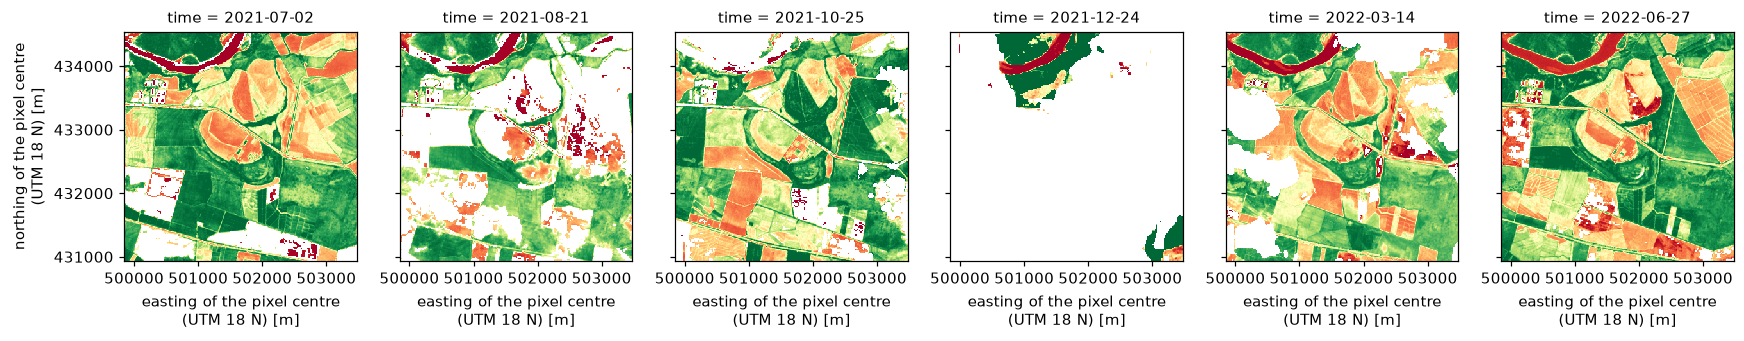

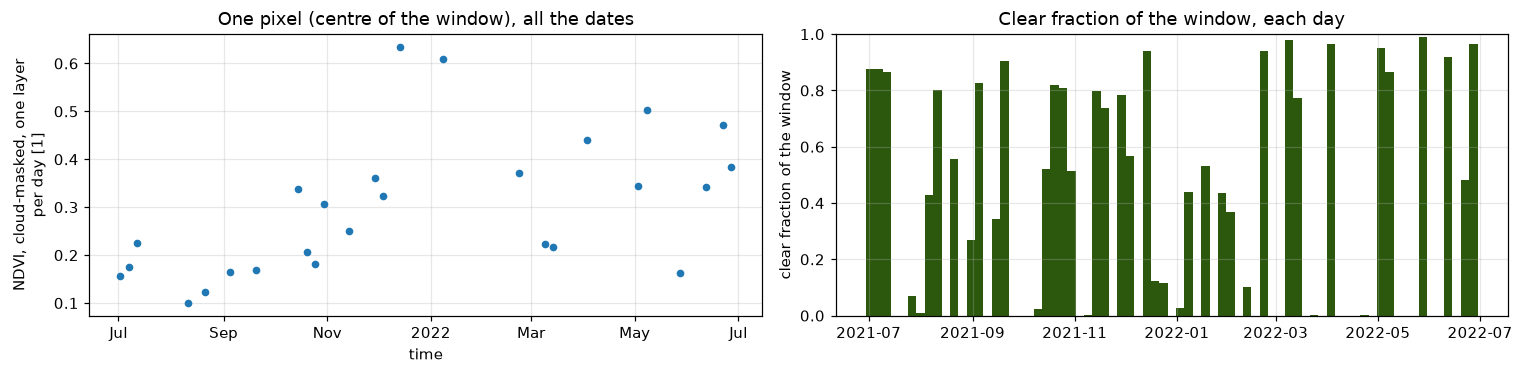

In [20]:
# (1) Six dates, evenly spread over the year: the cube "cut by time".
#   np.linspace gives 6 evenly spaced positions between the first and the last layer.
idx = np.linspace(0, n_days - 1, 6).astype(int)
ds["ndvi"].isel(time=idx).plot(col="time", col_wrap=6, cmap="RdYlGn", vmin=-0.1, vmax=0.9,
                               figsize=(16, 3.2), add_colorbar=False)
plt.show()

# Two more views, side by side: axes[0] (left) and axes[1] (right).
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))

# (2) One pixel, all the dates: the cube "cut by space" (the centre of the window).
#   Points only (linestyle="none"): these are separate observations, nothing in between.
ds["ndvi"].isel(y=ny // 2, x=nx // 2).plot(ax=axes[0], marker="o", ms=4, linestyle="none")
axes[0].set_title("One pixel (centre of the window), all the dates")

# (3) The clear fraction of each day: one BAR per day (a value per date, nothing in between).
#   Dates and values come from the provenance table, as in Part A (A4).
#   width=5 -> each bar is 5 days wide (images arrive about every 5 days).
prov = cube["provenance"]
axes[1].bar(pd.to_datetime(prov["date"]), prov["clear_fraction"], width=5, color="#2B580C")
axes[1].set_ylim(0, 1)                                    # 0 = all clouds, 1 = whole window clear
axes[1].set_ylabel("clear fraction of the window")
axes[1].set_title("Clear fraction of the window, each day")

plt.tight_layout(); plt.show()

# Part B · From irregular observations to a regular time series

### The problem
Our cube has a value only on the days Sentinel-2 passed and the pixel was clear. So each pixel has its own irregular calendar, with gaps of weeks in the rainy season, plus some values that are wrong even after the cloud mask (thin clouds, haze, shadows lower the NDVI).

Most time-series methods of the next sessions (anomalies, trends, phenology, change detection) need **the same regular dates for every pixel** and no holes. So we prepare the series in four steps (**the order matters**):

| Step | What it does | Function | Why in this position |
|---|---|---|---|
| 1. Remove dips | deletes sudden drops of NDVI that recover quickly | `remove_dips` | must be done on the **original** observations, before they are mixed into periods |
| 2. Regularise | one value per half-month: the median of its observations | `regularize` | gives every pixel the same calendar |
| 3. Fill short gaps | linear interpolation over gaps of up to one month | `fill_gaps` | needs a regular axis to know how long a gap is |
| 4. Smooth | Savitzky–Golay filter | `smooth_savgol` | needs a regular axis **without holes** |

> 💡 **Clarification — every step is a decision, not a correction.** Each step changes the data. A good analysis records which steps were applied, with which parameters, and checks that they did not invent or erase the signal it is looking for.

### B1 · Choose two pixels to follow

Compute, for every pixel, the 10th, 50th (median) and 90th percentiles of its NDVI over the year, and picks two pixels objectively:
* a **rice** pixel: the largest *amplitude* (90th − 10th percentile) among pixels with at least 15 clear days and a median above 0.3 (this excludes the river, whose large amplitude comes from water);
* a **stable vegetation** pixel (riparian forest): the highest median among pixels with a small amplitude (< 0.2).

**Why we need it.** We will watch what each step does to two very different signatures: a crop that changes fast, and vegetation that should be almost flat.

*Percentile 90* = the value below which 90 % of the observations of that pixel fall. We use percentiles instead of the minimum and maximum because a single bad value cannot move them much.

rice               row  66, col  92 | clear days 30 | median 0.31 | amplitude 1.13
stable vegetation  row  61, col  46 | clear days 27 | median 0.92 | amplitude 0.17


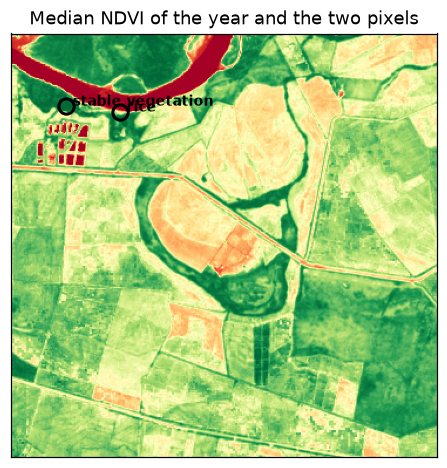

In [25]:
# The observed NDVI cube, read from the file (days, rows, columns).
ndvi_obs = cube["ndvi"]
ny, nx = ndvi_obs.shape[1], ndvi_obs.shape[2]             # number of rows and columns of the window

# --- Four summaries of the YEAR, for every pixel at once ---------------------------
# axis=0 means "along the time axis": each result is a MAP (rows x columns),
# with one value per pixel computed over all its dates.
#   np.isfinite(...) is True where there is a value (not NaN); summing the Trues
#   along time gives the number of clear days of each pixel.
n_clear = np.sum(np.isfinite(ndvi_obs), axis=0)
#   Percentiles of each pixel's NDVI over the year (nan... = ignore the NaN):
#   p10 = a "low" value (only 10 % of the dates are lower), p50 = the median,
#   p90 = a "high" value. We use percentiles instead of the minimum and the maximum
#   because a single bad value (a dip) cannot move them much.
p10 = np.nanpercentile(ndvi_obs, 10, axis=0)
p50 = np.nanpercentile(ndvi_obs, 50, axis=0)
p90 = np.nanpercentile(ndvi_obs, 90, axis=0)
#   Amplitude = how much the NDVI of the pixel changes during the year.
#   Large for a crop (bare field -> full canopy), small for a forest.
amplitude = p90 - p10

# --- Pick the RICE pixel: the one that changes most --------------------------------
#   np.where(condition, value, np.nan): keep the amplitude only where the pixel
#   (a) is well observed (at least 15 clear days) and (b) is mostly vegetation
#   (median above 0.3: this excludes the river, whose amplitude comes from water).
rice_score = np.where((n_clear >= 15) & (p50 > 0.3), amplitude, np.nan)
#   np.nanargmax finds the position of the largest value (ignoring NaN), counted
#   as if the map were one long line; np.unravel_index turns it into (row, column).
rice_row, rice_col = np.unravel_index(np.nanargmax(rice_score), rice_score.shape)

# --- Pick the STABLE VEGETATION pixel: green all year ------------------------------
#   Among well-observed pixels that change little (amplitude below 0.2),
#   the one with the highest median NDVI (e.g. a riparian forest).
forest_score = np.where((n_clear >= 15) & (amplitude < 0.2), p50, np.nan)
forest_row, forest_col = np.unravel_index(np.nanargmax(forest_score), forest_score.shape)

# The two pixels we will follow in every step of Part B, and their colours in the figures.
#   int(...) turns numpy numbers into plain integers.
PIXELS = {"rice": (int(rice_row), int(rice_col)), "stable vegetation": (int(forest_row), int(forest_col))}
COLOURS = {"rice": "#2B580C", "stable vegetation": "#7B4F9E"}
for name, (r, c) in PIXELS.items():
    print(f"{name:18s} row {r:3d}, col {c:3d} | clear days {n_clear[r, c]:2d} | "
          f"median {p50[r, c]:.2f} | amplitude {amplitude[r, c]:.2f}")

# Map of the median NDVI of the year, with the two pixels marked by circles.
#   In imshow, x = column and y = row: that is why we plot (c, r), not (r, c).
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(p50, cmap="RdYlGn", vmin=-0.1, vmax=0.9)
for name, (r, c) in PIXELS.items():
    ax.plot(c, r, "o", ms=10, mfc="none", mec="k", mew=2)     # empty circle around the pixel
    ax.text(c + 6, r, name, fontsize=9, weight="bold")       # its name, a little to the right
ax.set_title("Median NDVI of the year and the two pixels"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

> ✏️ **Your turn — choose your own pixels.** The automatic choice is only a starting point. Use the sliders to find **two pixels you want to compare**: one that **changes a lot** during the year (a crop) and one that **changes little** (stable vegetation, or something else you find interesting: a canal, a road, the river). Look at the map, the series and the summary of each one. Then run the next cell: all the steps of Part B will follow **your** two pixels.

In [26]:
# ✏️ EXPLORE: choose and compare TWO pixels with the sliders.
#   Pixel 1 (green): a pixel that CHANGES A LOT during the year (e.g. a crop).
#   Pixel 2 (purple): a pixel that CHANGES LITTLE (e.g. stable vegetation).
#   The sliders start at the pixels chosen automatically above. Move them: the map
#   shows where both pixels are, and the right panel compares their observed series.
#   (If the sliders do not appear: %pip install ipywidgets, then restart the kernel.)
from ipywidgets import interactive, IntSlider
from IPython.display import display

def compare_pixels(row1, col1, row2, col2):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
    # Left: the median NDVI of the year, with the two pixels marked
    axes[0].imshow(p50, cmap="RdYlGn", vmin=-0.1, vmax=0.9)
    axes[0].plot(col1, row1, "o", ms=12, mfc="none", mec=COLOURS["rice"], mew=2.5)
    axes[0].plot(col2, row2, "s", ms=12, mfc="none", mec=COLOURS["stable vegetation"], mew=2.5)
    axes[0].set_title("Median NDVI of the year"); axes[0].set_xticks([]); axes[0].set_yticks([])
    # Right: the observed series of both pixels (points only: separate observations)
    for (r, c, label, colour, marker) in ((row1, col1, "pixel 1 (changes a lot)", COLOURS["rice"], "o"),
                                          (row2, col2, "pixel 2 (changes little)", COLOURS["stable vegetation"], "s")):
        axes[1].plot(cube["time"], ndvi_obs[:, r, c], marker, ms=5, color=colour,
                     label=f"{label}: row {r}, col {c} | clear days {n_clear[r, c]} | "
                           f"median {p50[r, c]:.2f} | amplitude {amplitude[r, c]:.2f}")
    axes[1].set_ylim(-0.2, 1.0); axes[1].set_ylabel("NDVI"); axes[1].legend(fontsize=8, loc="lower left")
    axes[1].set_title("Observed series of the two pixels")
    plt.tight_layout(); plt.show()

# Four sliders: row and column of each pixel. They start at the automatic choice.
chooser = interactive(compare_pixels,
    row1=IntSlider(value=PIXELS["rice"][0], min=0, max=ny - 1, description="pixel 1 row"),
    col1=IntSlider(value=PIXELS["rice"][1], min=0, max=nx - 1, description="pixel 1 col"),
    row2=IntSlider(value=PIXELS["stable vegetation"][0], min=0, max=ny - 1, description="pixel 2 row"),
    col2=IntSlider(value=PIXELS["stable vegetation"][1], min=0, max=nx - 1, description="pixel 2 col"))
display(chooser)

interactive(children=(IntSlider(value=66, description='pixel 1 row', max=360), IntSlider(value=92, description…

In [27]:
# Use the TWO pixels you chose with the sliders in the rest of Part B.
#   chooser.kwargs holds the current position of the four sliders, so there is
#   nothing to copy by hand. Run this cell AFTER choosing your pixels.
#   (Skip this cell to keep the automatic choice.)
PIXELS["rice"] = (chooser.kwargs["row1"], chooser.kwargs["col1"])               # pixel 1: changes a lot
PIXELS["stable vegetation"] = (chooser.kwargs["row2"], chooser.kwargs["col2"])  # pixel 2: changes little
for name, (r, c) in PIXELS.items():
    print(f"{name:18s} row {r:3d}, col {c:3d} | clear days {n_clear[r, c]:2d} | "
          f"median {p50[r, c]:.2f} | amplitude {amplitude[r, c]:.2f}")

rice               row  66, col  92 | clear days 30 | median 0.31 | amplitude 1.13
stable vegetation  row  61, col  46 | clear days 27 | median 0.92 | amplitude 0.17


### B2 · The raw series, read directly from the file
We want to see the problem with our own eyes before trying to solve it: irregular spacing, gaps, and isolated drops. So, we read the two series with `tt.read_pixel_series`, which opens the HDF5 file and reads only the chunk that contains each pixel (thanks to the chunk design of Part A), and plots them.


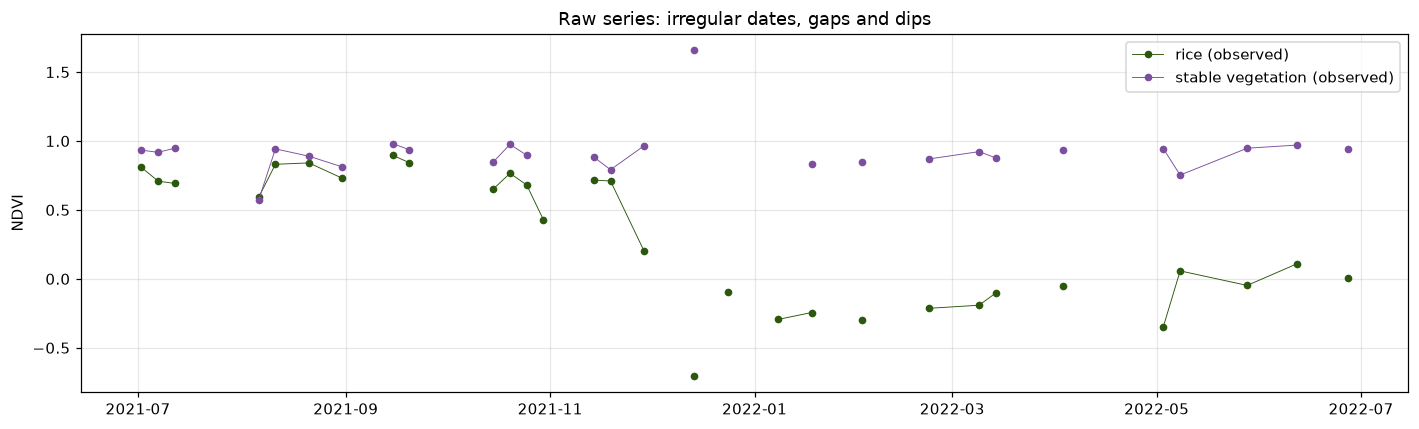

rice               clear dates: 30 of 45 | longest gap: 30 days
stable vegetation  clear dates: 27 of 45 | longest gap: 35 days


In [28]:
raw_series = {}
for name, (r, c) in PIXELS.items():
    raw_series[name] = tt.read_pixel_series(CUBE_FILE, r, c)

fig, ax = plt.subplots(figsize=(13, 4))
for name, s in raw_series.items():
    ax.plot(s.index, s.values, "o-", ms=4, lw=0.6, color=COLOURS[name], label=f"{name} (observed)")
ax.set_ylabel("NDVI"); ax.legend(); ax.set_title("Raw series: irregular dates, gaps and dips")
plt.tight_layout(); plt.show()

for name, s in raw_series.items():
    gaps = s.dropna().index.to_series().diff().dt.days
    print(f"{name:18s} clear dates: {s.notna().sum():2d} of {len(s)} | longest gap: {gaps.max():.0f} days")

🤔 **Reflect — Describe the two raw series. Which features are real, and which ones look like errors?**

<details><summary>Show a model answer (try first!)</summary>

The rice series should show one or two cycles: low values (flooded or bare field), a fast rise, a plateau near 0.8 and a sharp fall at harvest. The stable vegetation series should stay high (≈ 0.7–0.85). In both, isolated points that fall far below their neighbours and come back on the next date are typically residual clouds, haze or shadows that the SCL mask did not catch. A harvest also produces a fall, but it stays low for several dates — that difference is what Step 1 uses. The long gaps (weeks) usually occur in the rainy months.

</details>

### B3 · The cube as a table

We turn the cube (days, rows, columns) into a table with `tt.cube_to_table`: one row per date and one column per pixel. Pixel (row, col) becomes column number `row × columns + col` (`tt.pixel_column` does this calculation).

```
cube (46, 360, 360)                      table (46 rows × 129 600 columns)

   ┌────────┐                                         pixel 0   pixel 1   pixel 2   ...   pixel 129 599
  ┌────────┐│       tt.cube_to_table      2021-07-03    0.21      NaN       0.35    ...       0.78
 ┌────────┐││   ─────────────────────▶    2021-07-08    NaN       NaN       0.38    ...       0.80
 │        │┘┘                             ...
 └────────┘
```

**Nothing is computed: it is the same cube, reorganised.** The same values, in a different arrangement. And notice what each column is: **the time series of one pixel**. The table is the cube seen as a collection of time series — exactly what Part B wants to clean.

**Why a table?** The cube is a numpy array, and numpy knows nothing about dates: it cannot "group by half-month" or "interpolate according to the days elapsed". **pandas** can — but only on a table whose rows are dates. With the table, each step of Part B becomes one line that works on all the pixels at once with no loops over 129 600 pixels:

| Step | What pandas does, column by column |
|---|---|
| 1. Remove dips | `rolling(5, center=True).median()`: moving median of 5 dates |
| 2. Regularise | `resample("SMS").median()`: groups the dates into half-months |
| 3. Fill gaps | `interpolate(method="time")`: interpolates according to the days elapsed |
| 4. Smooth | the Savitzky–Golay filter runs along the rows (time) |

At the end, `tt.table_to_cube` does the opposite and puts the results back into a cube (B8), to save them and draw maps.

**How to find a pixel in the table.** Rows of the map are laid one after another, like reading a book: row 0 gives columns 0 to 359, row 1 gives columns 360 to 719, and so on. So the pixel in row 100, column 20 is column `100 × 360 + 20 = 36 020` of the table.

In [29]:
obs_table = tt.cube_to_table(cube["ndvi"], cube["time"])
print("table:", obs_table.shape[0], "dates x", obs_table.shape[1], "pixels")

COLUMNS = {}
for name, (r, c) in PIXELS.items():
    COLUMNS[name] = tt.pixel_column(r, c, nx)          # column of each of our two pixels
print(COLUMNS)
obs_table.iloc[:5, :5]                                  # the first 5 dates of the first 5 pixels

table: 45 dates x 131043 pixels
{'rice': 24050, 'stable vegetation': 22189}


,0,1,2,3,4
time,,,,,
2021-07-02,0.841797,0.831241,0.841584,0.851094,0.822105
2021-07-07,0.835722,0.806483,0.824814,0.806331,0.826952
2021-07-12,0.776818,0.756984,0.764843,0.723865,0.691771
2021-07-22,NaN,NaN,NaN,NaN,NaN
2021-07-27,NaN,NaN,NaN,NaN,NaN


### B4 · Step 1 — Remove dips

For each observation, `tt.remove_dips` computes the median of its neighbours (the 5 consecutive dates centred on it). If the value is lower than that median minus `threshold` (0.15 NDVI), it is considered a dip and removed (`NaN`). A value is judged only if there are at least 3 valid values around it.

**Why we need it.** Clouds and haze **lower** NDVI for one date. A real crop does not lose 0.15 and recover a few days later. A harvest also lowers NDVI, but then the neighbours are low too, so the median follows the harvest and the values are kept.

**The two parameters**:
* `window=5`: more neighbours = a more stable median, but a slower reaction to real changes;
* `threshold=0.15`: lower = more values removed (risk of deleting real changes); higher = more residual clouds survive.

removed 205829 of 3186124 clear observations (6.5 %)


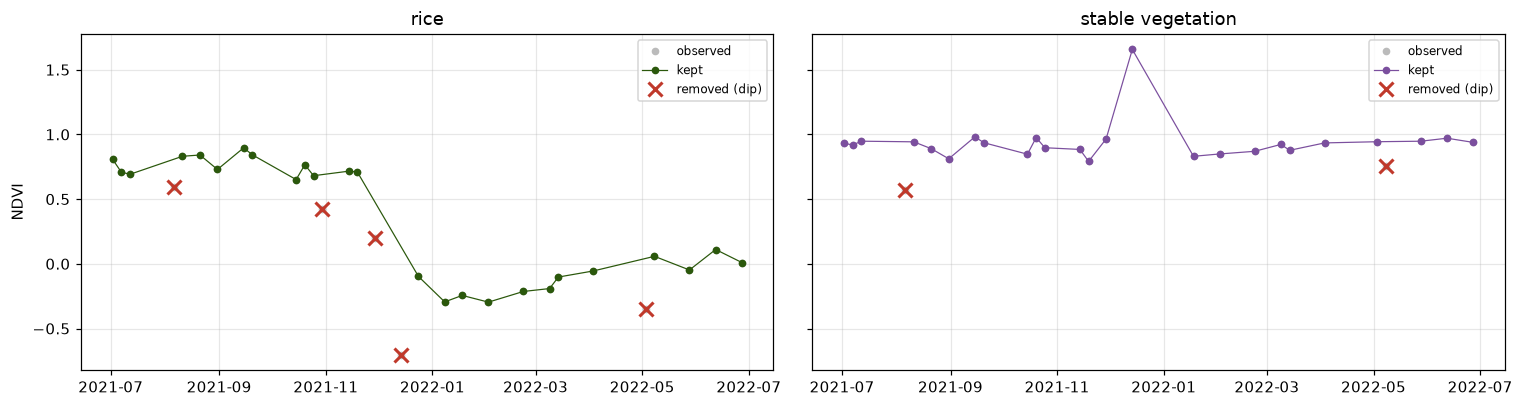

In [30]:
# STEP 1 · Remove dips (see the function in src/ts_tools.py, PART 4).
#   For every observation, tt.remove_dips computes the MEDIAN of its neighbours
#   (window=5: the 5 dates centred on it) and removes the value (-> NaN) if it is
#   more than threshold=0.15 below that median. It works on ALL the pixels at once.
#   It returns two things: the cleaned table and how many values were removed.
clean_table, n_removed = tt.remove_dips(obs_table, window=5, threshold=0.15)

# How many clear observations did we have? .notna() is True where there is a value;
#   .values.sum() counts the Trues of the whole table (all dates, all pixels).
n_valid = int(obs_table.notna().values.sum())

# Share of observations removed. Rule of thumb: if it is above ~10 %, suspect
#   the parameters (the threshold may be too low and deleting real changes).
print(f"removed {n_removed} of {n_valid} clear observations ({100 * n_removed / n_valid:.1f} %)")

# --- Look at what was removed in our two pixels --------------------------------
#   Two panels side by side; sharey=True = same NDVI scale in both, to compare them.
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)

# zip(axes, PIXELS) pairs each panel with one pixel name: left -> pixel 1, right -> pixel 2.
for ax, name in zip(axes, PIXELS):
    before = obs_table[COLUMNS[name]]           # the series of this pixel BEFORE step 1
    after = clean_table[COLUMNS[name]]          # the same series AFTER step 1
    # The removed values: those that had a value before (notna) and are empty after (isna).
    removed = before[before.notna() & after.isna()]

    # grey points = all the observations; coloured line = what was kept;
    # red crosses = what was removed as a dip.
    ax.plot(before.index, before.values, "o", ms=4, color="#BBBBBB", label="observed")
    ax.plot(after.dropna().index, after.dropna().values, "o-", ms=4, lw=0.8, color=COLOURS[name], label="kept")
    ax.plot(removed.index, removed.values, "x", ms=9, mew=2, color="#C0392B", label="removed (dip)")
    ax.set_title(name); ax.legend(fontsize=8)

axes[0].set_ylabel("NDVI")
plt.tight_layout(); plt.show()

# What to look for: each red cross should be a value that FALLS AND COMES BACK
#   (a cloud, haze or shadow). A harvest falls AND STAYS low: it must NOT be crossed.

### B4b · Optional — Another rule for dips: the Hampel filter
Removes dips with a second rule, `tt.remove_dips_hampel`, and compares it with the fixed threshold of B4. It does not change `clean_table`: the next steps keep using the result of B4.

Both rules compare each value with the median of its neighbours (the 5 dates centred on it). They differ in the threshold:

* **Fixed threshold B4:** a value is removed if it is more than 0.15 below the median. The same threshold everywhere.
* **Hampel filter:** a value is removed if it is more than k " standard deviations" below the median. The spread is measured with the **MAD** (median absolute deviation: the median distance between the values of the window and their median), multiplied by 1.4826 so that it estimates a standard deviation. Where the series is calm the threshold is small; where it is noisy, the threshold is larger. The threshold adapts to the local noise.

**The parameters**:
* `window=5`: number of dates in the window (odd);
* `k=3`: how many robust standard deviations below the median a value must be. Lower `k` = more values removed. `k = 3` is the most common choice;
* `min_sigma=0.02`: the smallest spread allowed. With only 3 or 4 valid values in a window, the MAD can be almost 0, and then any tiny difference would look like a dip.

**How to read the figure.** A **red ×** is a value removed by the fixed threshold; a **blue circle** is a value removed by Hampel. A × inside a circle was removed by both. Where they disagree, ask yourself: is it a cloud, or a real change?

> ⚠️ **No rule is "the correct one".** Two reasonable rules remove different values. Removing dips is a **decision**, and the parameters must be reported.

fixed threshold (0.15): removed 205829 values (6.5 %)
Hampel (k = 3):         removed 104841 values (3.3 %)
removed only by the fixed threshold: 135507
removed only by Hampel:              34519


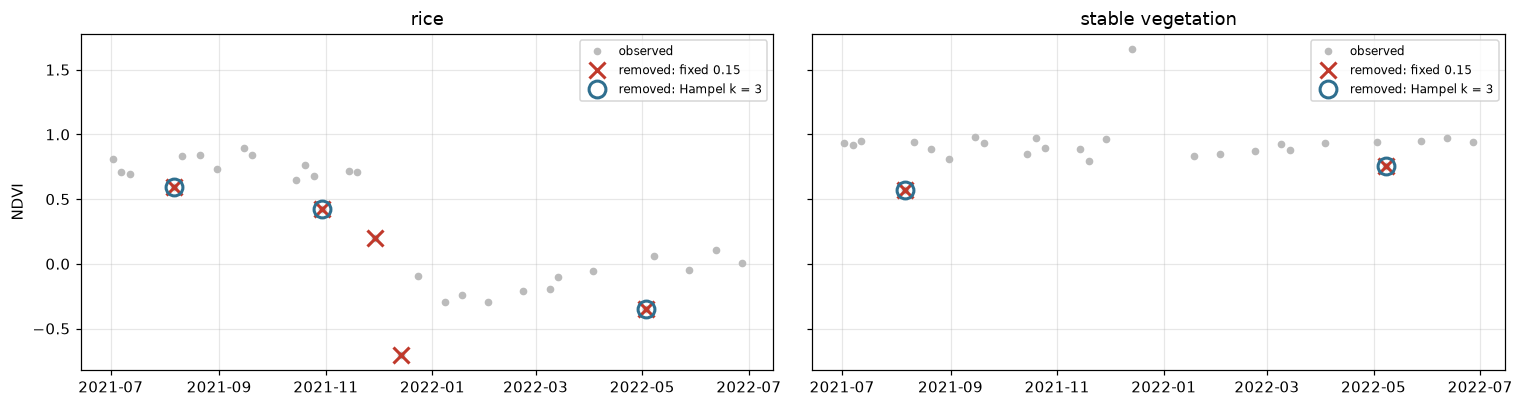

In [9]:
# OPTIONAL COMPARISON: fixed threshold vs Hampel filter.
# Both compare each value with the median of its 5 neighbouring dates.
#   remove_dips        -> removes a value if it is more than 0.15 below that median
#   remove_dips_hampel -> removes it if it is more than k = 3 "robust standard
#                         deviations" below: the threshold adapts to the local noise
# We keep clean_table (fixed threshold) for the next steps; this cell only compares.
hampel_table, n_hampel = tt.remove_dips_hampel(obs_table, window=5, k=3)

print(f"fixed threshold (0.15): removed {n_removed} values ({100 * n_removed / n_valid:.1f} %)")
print(f"Hampel (k = 3):         removed {n_hampel} values ({100 * n_hampel / n_valid:.1f} %)")

# Where do the two rules disagree? Values removed by one rule and kept by the other.
only_fixed = (clean_table.isna() & hampel_table.notna()).values.sum()
only_hampel = (hampel_table.isna() & clean_table.notna()).values.sum()
print(f"removed only by the fixed threshold: {only_fixed}")
print(f"removed only by Hampel:              {only_hampel}")

# Plot both rules on the two example pixels
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, name in zip(axes, PIXELS):
    before = obs_table[COLUMNS[name]]
    fixed = clean_table[COLUMNS[name]]
    hampel = hampel_table[COLUMNS[name]]
    ax.plot(before.index, before.values, "o", ms=4, color="#BBBBBB", label="observed")
    removed_fixed = before[before.notna() & fixed.isna()]
    removed_hampel = before[before.notna() & hampel.isna()]
    ax.plot(removed_fixed.index, removed_fixed.values, "x", ms=10, mew=2, color="#C0392B", label="removed: fixed 0.15")
    ax.plot(removed_hampel.index, removed_hampel.values, "o", ms=11, mfc="none", mew=2, color="#2F6F8F", label="removed: Hampel k = 3")
    ax.set_title(name); ax.legend(fontsize=8)
axes[0].set_ylabel("NDVI")
plt.tight_layout(); plt.show()

> ✏️ **Your turn.** Run the cell again with `k=2` and `k=4`. How many values are removed each time? With which `k` does Hampel start to delete real changes in the rice pixel?

### B5 · Step 2 — Regularise: one value per half-month

`tt.regularize` groups the dates into half-months (from the 1st to the 14th, and from the 15th to the end of the month; pandas code `"SMS"`) and gives each period the median of its clear observations. Periods with no observation stay empty (`NaN`). It also returns how many observations each period used.

**Why half-months?** The step must be shorter than the events we want to see. A rice season lasts about four months and the rise takes a few weeks: with half-months (24 values a year) we keep its shape; with months (12 values) the peaks start to blur. Shorter steps (a week) would leave most periods empty, because Sentinel-2 sees a clear Saldaña only every one or two weeks.


In [10]:
regular_table, n_obs_table = tt.regularize(clean_table, step="SMS")

empty_share = regular_table.isna().values.mean()
print(f"regular table: {regular_table.shape[0]} half-months x {regular_table.shape[1]} pixels")
print(f"empty periods: {100 * empty_share:.1f} % of all pixel-periods")
print("observations per period, rice pixel:", n_obs_table[COLUMNS["rice"]].values)
regular_table.index[:4]

regular table: 24 half-months x 131043 pixels
empty periods: 33.8 % of all pixel-periods
observations per period, rice pixel: [3 0 1 2 0 2 0 3 1 1 0 1 1 1 1 1 2 0 1 0 1 1 1 1]


DatetimeIndex(['2021-07-01', '2021-07-15', '2021-08-01', '2021-08-15'], dtype='datetime64[us]', name='time', freq='SMS-15')

### B6 · Step 3 — Fill short gaps

`tt.fill_gaps` fills empty periods by **linear interpolation in time** (a straight line between the values before and after the gap), but only if the gap is at most `max_gap` periods long (2 half-months ≈ one month). Longer gaps stay empty. A short gap at the very beginning or end of the year receives the nearest value.

Smoothing (Step 4) and most analysis methods cannot work with holes. But filling a gap of three months would invent a whole part of the crop cycle, so we only fill what we can reasonably estimate, and we count how much we filled.

The map on the right shows, for every pixel, how many half-months are still empty after filling. Those holes stay empty: the next step smooths only the stretches between them, and later analyses must treat these pixels with care.

filled 848484 pixel-periods (27.0 % of the table)
pixels with no hole left: 63.1 %


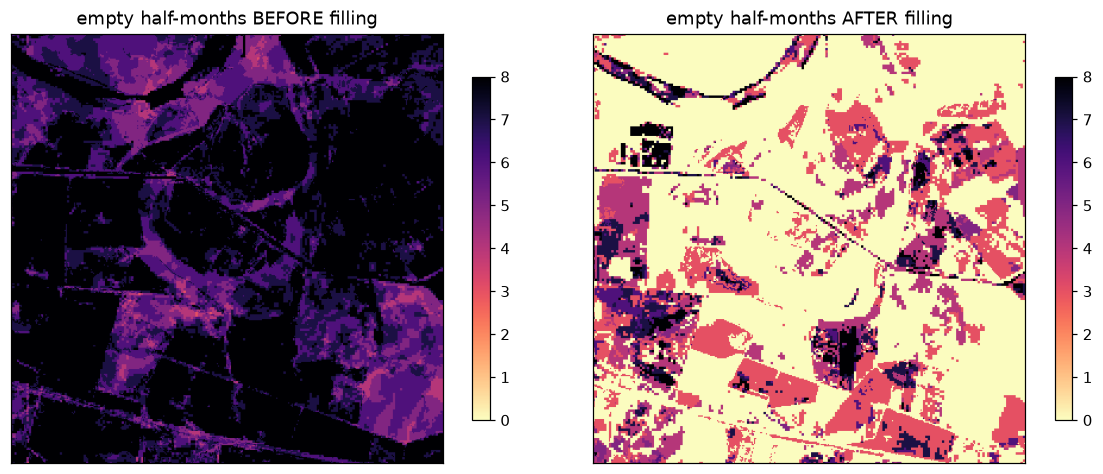

In [32]:
# STEP 3 · Fill SHORT gaps (see the function in src/ts_tools.py, PART 4).
#   tt.fill_gaps fills the empty half-months by linear interpolation in time
#   (a straight line between the value before and the value after the gap),
#   but ONLY if the gap lasts at most max_gap=2 periods (about one month).
#   Longer gaps stay empty: filling them would be inventing data.
#   It returns two things: the filled table and how many values were filled.
filled_table, n_filled = tt.fill_gaps(regular_table, max_gap=2)

# How much of the table is now an ESTIMATE instead of an observation?
#   .size = total number of cells of the table (periods x pixels).
n_cells = regular_table.size
print(f"filled {n_filled} pixel-periods ({100 * n_filled / n_cells:.1f} % of the table)")

# How many empty half-months are LEFT in each pixel (the long gaps we did not fill)?
#   .isna() is True where there is no value; .sum(axis=0) counts them down each
#   column, so we get one number per pixel.
still_empty = filled_table.isna().sum(axis=0)
#   Share of pixels with a complete series (0 empty periods): they are the ones
#   that can be smoothed in one piece in step 4.
print(f"pixels with no hole left: {100 * (still_empty == 0).mean():.1f} %")

# --- Two maps: empty half-months per pixel, BEFORE and AFTER filling ---------------
#   .values.reshape(ny, nx) turns the list of 129 600 pixels (one per column of the
#   table) back into a map of rows x columns, to draw it with imshow.
#   Same colour scale in both maps (vmin=0, vmax=8) so they can be compared:
#   light = few empty half-months, dark = many.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
im = axes[0].imshow(regular_table.isna().sum(axis=0).values.reshape(ny, nx), cmap="magma_r", vmin=0, vmax=8)
axes[0].set_title("empty half-months BEFORE filling"); plt.colorbar(im, ax=axes[0], shrink=0.8)
im = axes[1].imshow(still_empty.values.reshape(ny, nx), cmap="magma_r", vmin=0, vmax=8)
axes[1].set_title("empty half-months AFTER filling"); plt.colorbar(im, ax=axes[1], shrink=0.8)
for a in axes: a.set_xticks([]); a.set_yticks([])            # hide the axis numbers (pixel indices)
plt.tight_layout(); plt.show()

# What to look for: the map should become much lighter (short gaps filled), but
#   NOT completely white: the pixels that stay dark had long gaps (clouds for more
#   than a month), and we left them empty on purpose.

### B7 · Step 4 — Smooth with a Savitzky–Golay filter

`tt.smooth_savgol` replaces each value by the value of a small parabola (polynomial of degree `order=2`) fitted to the `window=5` half-months around it (two before, the value itself, two after). The filter cannot jump over a hole: in pixels that still have holes, each stretch without holes is smoothed separately (if it has at least 5 values).

**Why Savitzky–Golay?** A simple moving average also smooths, but it lowers peaks and widens valleys. Fitting a parabola follows a curved peak better, so the height and the date of the maximum — key for phenology (Session 3) — change less. It is one of the most used filters for NDVI series (Chen et al., 2004).

**The risk.** Too large a window (or a too regular step) flattens real peaks; too small a window does nothing (a parabola through 3 points passes **exactly** through them). Smoothing must remove noise, not the crop.

**This cell then plots the four steps together** for the two pixels: the most important figure of the session.

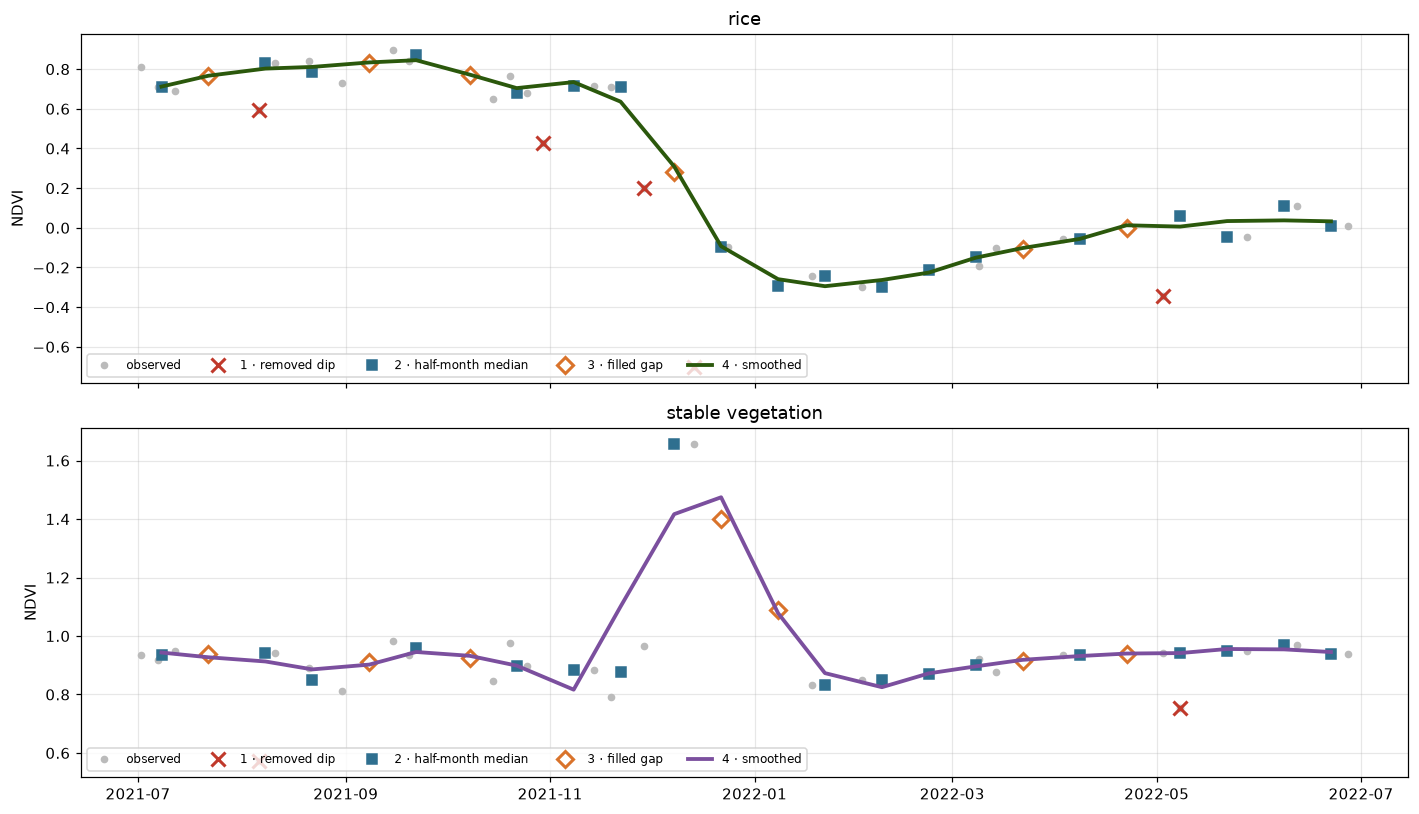

In [33]:
# STEP 4 · Smooth with a Savitzky–Golay filter (see the function in src/ts_tools.py, PART 4).
#   For every half-month, the filter fits a small parabola (order=2) to the 5 periods
#   around it (window=5: two before, itself, two after) and keeps the value of the
#   parabola at the centre. It removes small zig-zags but keeps the height and the
#   date of the peaks better than a moving average.
#   The filter cannot jump over holes: in pixels that still have long gaps, each
#   stretch without holes is smoothed separately.
smooth_table = tt.smooth_savgol(filled_table, window=5, order=2)

# Each half-month is labelled with its FIRST day (1st or 15th). To draw each value
#   in the MIDDLE of its period, we move it 7 days forward (only for the plot).
mid = smooth_table.index + pd.Timedelta(days=7)

# --- The four steps on our two pixels, one panel per pixel -------------------------
#   2 rows x 1 column of panels; sharex=True = the same time axis in both.
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for ax, name in zip(axes, PIXELS):
    col_k = COLUMNS[name]                       # the column of this pixel in the tables

    # The original observations (grey points): the evidence.
    ax.plot(obs_table.index, obs_table[col_k], "o", ms=4, color="#BBBBBB", label="observed")

    # Step 1: the values removed as dips = had a value before, empty after step 1.
    removed = obs_table[col_k][obs_table[col_k].notna() & clean_table[col_k].isna()]
    ax.plot(removed.index, removed.values, "x", ms=9, mew=2, color="#C0392B", label="1 · removed dip")

    # Step 2: the median of each half-month (blue squares), placed in the middle of the period.
    ax.plot(mid, regular_table[col_k], "s", ms=6, color="#2F6F8F", label="2 · half-month median")

    # Step 3: the periods that were EMPTY after step 2 and got a value in step 3.
    #   They are ESTIMATES, not observations, so we draw them differently
    #   (white diamonds with an orange border).
    was_empty = regular_table[col_k].isna() & filled_table[col_k].notna()
    ax.plot(mid[was_empty.values], filled_table[col_k][was_empty], "D", ms=7, mfc="white",
            mec="#D9732B", mew=2, label="3 · filled gap")

    # Step 4: the smoothed series (thick line): the final, regular series of the pixel.
    ax.plot(mid, smooth_table[col_k], "-", lw=2.5, color=COLOURS[name], label="4 · smoothed")

    ax.set_ylabel("NDVI"); ax.set_title(name); ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

# What to look for: the thick line should follow the grey points without the
#   zig-zags, keep the height of the peaks, and fall where the harvests fall.
#   Be careful where the line passes through white diamonds: there it rests on
#   estimates, not on observations.

🤔 **Reflect — Look at the rice panel. What did each step change? Is there any place where the final curve says something the observations do not support?**

<details><summary>Show a model answer (try first!)</summary>

Step 1 removed isolated drops that came back on the next date. Step 2 put one value every half-month, collapsing dates that fall in the same period and leaving empty periods where no clear image existed. Step 3 drew straight lines across short gap, those diamonds are **estimates**, not observations. Step 4 removed small zig-zags. Places to be careful: (a) a*filled gap at a peak or a valley: if the true maximum fell inside a gap, the filled value lies on a straight line and **underestimates the peak**, and the smoothed curve inherits that error; (b) a **sharp harvest**: the observations drop from about 0.8 to 0.2 between two dates, but the smoothed curve starts falling **earlier** and more gently, so a harvest date read from the smoothed curve would be too early; (c) the **edges** of each stretch, where the filter has neighbours on one side only. A good habit is to keep the count of observations per period (`n_obs_table`) next to the smoothed series and distrust periods built on zero observations.

</details>

### B8 · Store the regular cube, with its recipe

Turn the smoothed table back into a cube (`tt.table_to_cube`), builds a small provenance table per half-month (median number of observations used, share of pixels filled) and saves everything with `tt.save_cube_hdf5` into a new file, whose global attributes record the recipe: source file and the four steps with their parameters.

**Why a new file instead of overwriting?** The observed cube is the evidence; the regular cube is an interpretation of it. Keeping both lets you change the recipe later (another step, another filter) without downloading anything again.

In [41]:
# --- 1) Build the REGULAR cube: same structure as the observed cube of Part A -------
#   A dictionary with the same five parts, so the same function can save it.
regular_cube = {
    # tt.table_to_cube does the OPPOSITE of cube_to_table: from the table
    # (periods x pixels) back to a cube (periods, rows, columns).
    "ndvi": tt.table_to_cube(smooth_table, ny, nx),
    # The time axis is now REGULAR: 24 half-months, the same for every pixel.
    #   Each period is labelled with its first day (the 1st or the 15th).
    "time": smooth_table.index,
    # Same grid as the observed cube: the coordinates do not change.
    "x": cube["x"],
    "y": cube["y"],
    # Provenance of the REGULAR cube: one row per half-month, telling how much of
    #   each period rests on real observations and how much is estimated.
    "provenance": pd.DataFrame({
        # the first day of the period, as text
        "period_start": smooth_table.index.strftime("%Y-%m-%d"),
        # how many clear observations a typical pixel had in that period (step 2);
        #   .median(axis=1) = the median across all the pixels, period by period
        "median_obs_per_pixel": n_obs_table.median(axis=1).values,
        # share of pixels whose value in that period was FILLED (step 3), i.e. estimated:
        #   empty after step 2 AND with a value after step 3; .mean(axis=1) = the share
        "share_pixels_filled": (regular_table.isna() & filled_table.notna()).mean(axis=1).values,
    }),
}

# --- 2) The RECIPE: the global attributes of the new file ---------------------------
#   Start from the attributes of the observed cube, read from its file (grid, CRS,
#   source, and the decisions of cube E3): the regular cube inherits them.
recipe = dict(cube["attrs"])
#   Remove "title" and "created": they describe the OBSERVED file. The new file
#   gets its own title (below) and its own creation date.
recipe.pop("title", None); recipe.pop("created", None)
#   Add what Part B did: where the data come from and the four steps, WITH their
#   parameters. Anyone who opens the file will know exactly how it was prepared.
recipe.update({
    "derived_from": CUBE_FILE,                        # the evidence this interpretation comes from
    "step1_remove_dips": "rolling median of 5 dates, threshold 0.15, min 3 observations",
    "step2_regularize": "half-month periods (pandas 'SMS'), median of clear observations",
    "step3_fill_gaps": "linear interpolation in time, gaps of at most 2 periods",
    "step4_smooth": "Savitzky-Golay, window 5 periods, polynomial order 2",
    "time_note": "time = first day of each half-month period",
})

# --- 3) Save it in a NEW file (we do not overwrite the observed cube) ----------------
#   The observed cube is the EVIDENCE; this regular cube is an INTERPRETATION of it.
#   Keeping both lets us change the recipe later without downloading anything again.
#   chunks=(24, 40, 40): the whole year (24 half-months) of a block of 40 x 40 pixels
#   in ONE chunk -> designed again for reading pixel time series (as in Part A, A5).
tt.save_cube_hdf5(REGULAR_FILE, regular_cube, chunks=(24, 40, 40), attrs=recipe,
                 title="REGULAR half-month NDVI cube (dips removed, gaps filled, smoothed)")

# Check what is inside the new file: datasets, chunks, compression and the recipe.
tt.describe_hdf5(REGULAR_FILE)

/
  ndvi                         shape=(24, 361, 363)   float32  chunks=(24, 40, 40)   compression=gzip
provenance/
  provenance/median_obs_per_pixel shape=(24,)            float64  chunks=(24,)          compression=None
  provenance/period_start      shape=(24,)            |S10     chunks=(24,)          compression=None
  provenance/share_pixels_filled shape=(24,)            float64  chunks=(24,)          compression=None
  time                         shape=(24,)            float64  chunks=(24,)          compression=None
  x                            shape=(363,)           float64  chunks=None           compression=None
  y                            shape=(361,)           float64  chunks=None           compression=None

Global attributes:
  aoi_bbox_lonlat: [-75.0013   3.8987 -74.9687   3.9313]
  clear_classes: SCL in (4, 5, 6): vegetation, not vegetated, water
  coordinates_note: x, y are pixel CENTRES
  created: 2026-11-10 11:36
  crs: EPSG:32618
  derived_from: saldana_ndvi_cube

### B8b · Explore the new file

The regular cube is now on disk. Before using it, we look inside the file: its structure (groups, datasets, attributes), how the NDVI is stored (chunks, compression) and where the chunks fall on the map.

### The same structure, as a picture

This is the file you just saved, `saldana_ndvi_semimonthly.h5`, drawn as boxes:

- **Green:** the file and its groups (like folders).
- **Blue:** the datasets (the data), with their shape, data type, chunks and compression.
- **Orange:** the attributes (the metadata), marked with `@`. The global attributes are the recipe of the cube.

Read it from left to right: the file contains four datasets (`x`, `y`, `time`, `ndvi`) and one group (`provenance/`), and the group contains its own datasets.

[Structure of saldana_ndvi_semimonthly.h5](https://drive.google.com/file/d/1pkYq9-HPqxQkZ8OSS7DiNlxX7tzUGxdm/view?usp=sharing)

In [44]:
import h5py

with h5py.File(REGULAR_FILE, "r") as f:
    d = f["ndvi"]                                          # the NDVI dataset (not loaded: just its description)
    print("shape (periods, rows, columns):", d.shape)
    print("data type:", d.dtype, "| bytes per value:", d.dtype.itemsize)
    print("chunk shape:", d.chunks)                        # how the cube is cut into blocks
    print("compression:", d.compression, "| level:", d.compression_opts, "| shuffle:", d.shuffle)
    print("can grow in time (maxshape):", d.maxshape)       # None = no limit on that axis

    # How many chunks along each axis, and in total (ceil = round up: a partial chunk counts)
    per_axis = [int(np.ceil(s / c)) for s, c in zip(d.shape, d.chunks)]
    print("chunks per axis (time, y, x):", per_axis, "-> total:", int(np.prod(per_axis)))

    # Size of the data: in memory (uncompressed) vs on disk (compressed)
    raw_mb = d.size * d.dtype.itemsize / 1e6
    disk_mb = d.id.get_storage_size() / 1e6                # bytes actually written for this dataset
    print(f"uncompressed: {raw_mb:.1f} MB | on disk: {disk_mb:.1f} MB | ratio: {raw_mb / disk_mb:.1f}x")

shape (periods, rows, columns): (24, 361, 363)
data type: float32 | bytes per value: 4
chunk shape: (24, 40, 40)
compression: gzip | level: 4 | shuffle: True
can grow in time (maxshape): (None, 361, 363)
chunks per axis (time, y, x): [1, 10, 10] -> total: 100
uncompressed: 12.6 MB | on disk: 9.3 MB | ratio: 1.4x


### Looking inside the chunks

The `ndvi` dataset is not stored as one big block. HDF5 cuts it into chunks of 24 × 40 × 40 values: the whole year for a square of 40 × 40 pixels. With a 360 × 360 pixel grid, that gives 9 × 9 = 81 chunks. Each chunk is compressed on its own and written somewhere in the file. When you read a pixel series, HDF5 finds the one chunk that contains that pixel and decompresses only that one.

The next cell asks the file about each chunk:

- **starts at (time, row, col):** where the block begins in the cube. For example, `(0, 40, 80)` is the chunk that covers rows 40–79 and columns 80–119 for all 24 periods. The time index is always 0, because each chunk holds the full year.
- **compressed size (kB):** how much space the chunk takes on disk after gzip. Without compression, every chunk weighs the same: 24 × 40 × 40 values × 4 bytes (float32) ≈ 154 kB.
- **position in the file (byte):** the address where the chunk starts inside the `.h5` file. The chunks do not have to be stored in order; HDF5 keeps an index that points to each one.

Look at how much the compressed sizes vary. Compression works better where the values repeat or change little: chunks with many empty pixels (NaN) or homogeneous cover shrink a lot, while chunks with heterogeneous fields and edges shrink less. The same cube can take very different space depending on what it shows.

In [45]:
# Every chunk is stored as an independent compressed block inside the file.
#   get_chunk_info(i) tells, for chunk number i: its position in the cube (offset)
#   and its size on disk after compression.
with h5py.File(REGULAR_FILE, "r") as f:
    d = f["ndvi"]
    rows = []
    for i in range(d.id.get_num_chunks()):
        info = d.id.get_chunk_info(i)
        rows.append({"chunk": i,
                     "starts at (time, row, col)": info.chunk_offset,     # first index of the block
                     "compressed size (kB)": round(info.size / 1e3, 1),
                     "position in the file (byte)": info.byte_offset})
chunks_table = pd.DataFrame(rows)
display(chunks_table.head(10))
print("compressed size of one chunk: from", chunks_table["compressed size (kB)"].min(),
      "to", chunks_table["compressed size (kB)"].max(), "kB (uncompressed: 24 x 40 x 40 x 4 B = 154 kB)")

,chunk,"starts at (time, row, col)",compressed size (kB),position in the file (byte)
0,0,"(0, 0, 0)",113.6,19216
1,1,"(0, 0, 40)",110.0,132833
2,2,"(0, 0, 80)",110.7,242880
3,3,"(0, 0, 120)",116.3,353585
4,4,"(0, 0, 160)",118.8,469865
5,5,"(0, 0, 200)",113.3,588662
6,6,"(0, 0, 240)",117.0,702002
7,7,"(0, 0, 280)",118.3,819042
8,8,"(0, 0, 320)",118.4,937361
9,9,"(0, 0, 360)",15.0,5157078


compressed size of one chunk: from 0.7 to 119.9 kB (uncompressed: 24 x 40 x 40 x 4 B = 154 kB)


### Where the chunks fall on the map

The table above listed the chunks by number. Now we put them on the map. The next cell draws one half-month of NDVI and lays the chunk grid on top: each black square is one chunk, 40 × 40 pixels.

A map shows only one period, but each square in the file holds all 24 half-months of its pixels. Picture each square as a column that goes down through time. This is what makes the file series-friendly:

- **A pixel series:** you need the column under one pixel. It falls inside a single square, so HDF5 reads 1 chunk.
- **A map of one half-month:** you need one layer across the whole area. It cuts through every square, so HDF5 reads 81 chunks, and from each one it keeps only 1 of the 24 periods it decompressed.

Pick any pixel on the map and find its square. That square is all the file has to open to give you that pixel's series.

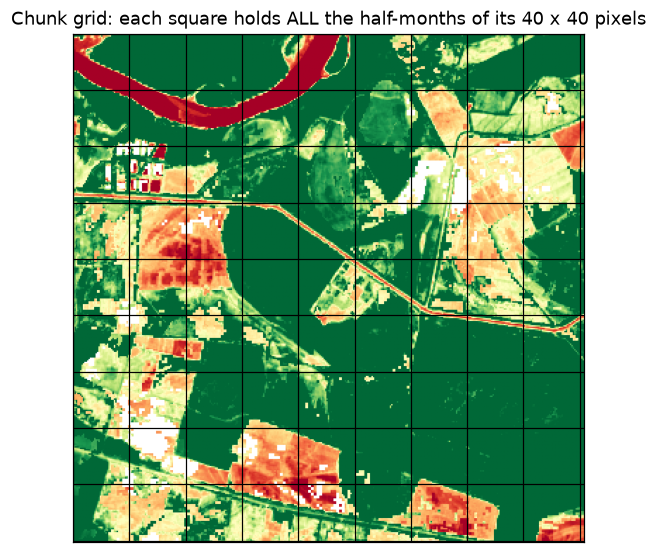

In [46]:
# Where the chunks fall on the map: one square = one chunk (40 x 40 pixels, all 24 periods).
with h5py.File(REGULAR_FILE, "r") as f:
    one_map = f["ndvi"][10]                                # any half-month
    cy, cx = f["ndvi"].chunks[1], f["ndvi"].chunks[2]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(one_map, cmap="RdYlGn", vmin=-0.1, vmax=0.9)
for k in range(0, one_map.shape[0] + 1, cy): ax.axhline(k - 0.5, color="k", lw=0.8)
for k in range(0, one_map.shape[1] + 1, cx): ax.axvline(k - 0.5, color="k", lw=0.8)
ax.set_title("Chunk grid: each square holds ALL the half-months of its 40 x 40 pixels")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

### B9 · The year at a glance

Draw the 24 half-month NDVI maps of the regular cube.

Every pixel now has a value on the same dates, so we can compare the whole district period by period. You should see blocks of paddies turning green and brown at different moments — the farmers do not all sow on the same day. Grey pixels are those that still have holes.

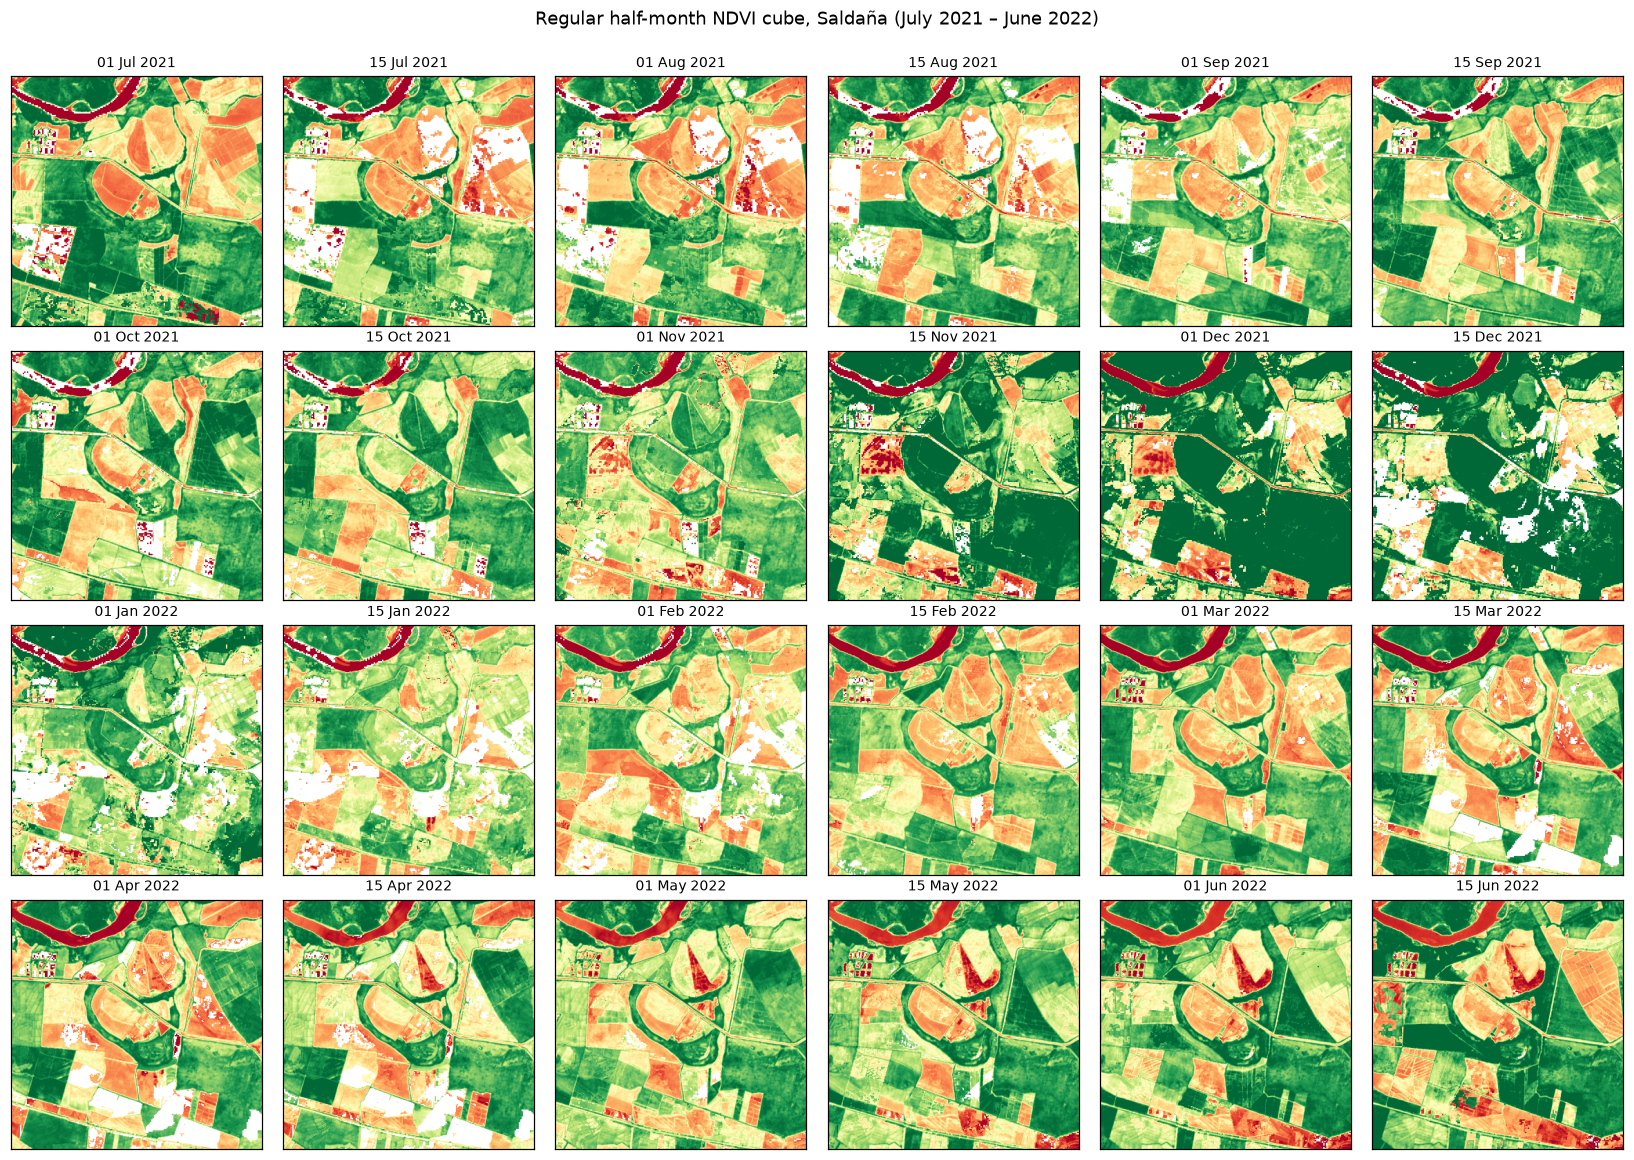

In [35]:
# The NDVI of the regular cube: (24 half-months, rows, columns).
reg_ndvi = regular_cube["ndvi"]

# A grid of 4 rows x 6 columns = 24 small maps: ONE MAP PER HALF-MONTH, the whole year.
#   This is the cube "cut by time", period after period.
fig, axes = plt.subplots(4, 6, figsize=(15, 10.5))

# axes.ravel() turns the 4 x 6 grid of panels into one list of 24 panels, in reading
#   order (left to right, top to bottom); enumerate gives the number k of each panel.
for k, ax in enumerate(axes.ravel()):
    if k < reg_ndvi.shape[0]:                   # only if the cube has a period number k
        # The map of period k, with the same colour scale in every panel
        #   (vmin, vmax), so the colours can be compared from one map to the next.
        ax.imshow(reg_ndvi[k], cmap="RdYlGn", vmin=-0.1, vmax=0.9)
        # Title: the first day of the half-month, e.g. "01 Jul 2021" (%d day, %b month, %Y year).
        ax.set_title(regular_cube["time"][k].strftime("%d %b %Y"), fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)   # clean panels: no axis numbers, no grid

plt.suptitle("Regular half-month NDVI cube, Saldaña (July 2021 – June 2022)", y=1.0)
plt.tight_layout(); plt.show()

# What to look for: compare with the maps of the observed cube (section 0.4). There,
#   many dates had holes (clouds); here every half-month has a complete map, except
#   in the pixels with long gaps we did not fill. Follow one field through the year:
#   it turns green as the rice grows and brown after the harvest — twice a year.

### B10 · Two files, side by side: evidence and interpretation

We did **not** overwrite the observed cube: we created a **second file**. Now we open **both files** and compare what each one contains:

* `saldana_ndvi_cube.h5` — the **evidence**: the observations as they were, on irregular dates, with their holes.
* `saldana_ndvi_semimonthly.h5` — the **interpretation**: a regular, gap-filled, smoothed version, with the recipe that produced it.

The second file **keeps** everything that describes the grid and the decisions of cube E3, and **adds** the four preparation steps. Both are read from disk: nothing comes from the memory of the notebook.

In [36]:
import os

# Open BOTH files from disk (not the variables in memory).
observed = tt.load_cube_hdf5(CUBE_FILE)        # the evidence (Part A)
regular = tt.load_cube_hdf5(REGULAR_FILE)      # the interpretation (Part B)

# --- 1) Side-by-side summary of the two cubes -----------------------------------------
#   For each file: shape, dates, how regular the time axis is, holes and size on disk.
def summary(c, path):
    steps = pd.Series(c["time"]).diff().dt.days.dropna()          # days between consecutive layers
    return {
        "layers (time)": c["ndvi"].shape[0],
        "rows x columns": f"{c['ndvi'].shape[1]} x {c['ndvi'].shape[2]}",
        "first date": c["time"][0].date(),
        "last date": c["time"][-1].date(),
        "days between layers": f"{steps.min():.0f} to {steps.max():.0f}",   # regular -> almost constant
        "empty values (NaN)": f"{100 * np.isnan(c['ndvi']).mean():.1f} %",
        "size on disk (MB)": round(os.path.getsize(path) / 1e6, 1),
    }

comparison = pd.DataFrame({"observed (evidence)": summary(observed, CUBE_FILE),
                           "regular (interpretation)": summary(regular, REGULAR_FILE)})
display(comparison)

# --- 2) The recipe: what was KEPT and what was ADDED ---------------------------------
#   Compare the names of the global attributes of the two files.
obs_keys = set(observed["attrs"])
reg_keys = set(regular["attrs"])
print("Attributes in BOTH files (inherited: grid, source, decisions of cube E3):")
for k in sorted(obs_keys & reg_keys):           # & = in both
    print("  ", k)
print("\nAttributes ONLY in the regular file (added by Part B: the preparation recipe):")
for k in sorted(reg_keys - obs_keys):           # - = in the regular file but not in the observed one
    print(f"   {k:18s}: {regular['attrs'][k]}")

# --- 3) The provenance: one row per DAY vs one row per HALF-MONTH ---------------------
print("\nProvenance columns, observed:", list(observed["provenance"].columns))
print("Provenance columns, regular: ", list(regular["provenance"].columns))

,observed (evidence),regular (interpretation)
layers (time),45,24
rows x columns,361 x 363,361 x 363
first date,2021-07-02,2021-07-01
last date,2022-06-27,2022-06-15
days between layers,5 to 20,14 to 17
empty values (NaN),46.0 %,6.9 %
size on disk (MB),10.6,9.3


Attributes in BOTH files (inherited: grid, source, decisions of cube E3):
   aoi_bbox_lonlat
   clear_classes
   coordinates_note
   created
   crs
   duplicate_rule
   offset_rule
   period
   resolution_m
   source
   title

Attributes ONLY in the regular file (added by Part B: the preparation recipe):
   derived_from      : saldana_ndvi_cube.h5
   step1_remove_dips : rolling median of 5 dates, threshold 0.15, min 3 observations
   step2_regularize  : half-month periods (pandas 'SMS'), median of clear observations
   step3_fill_gaps   : linear interpolation in time, gaps of at most 2 periods
   step4_smooth      : Savitzky-Golay, window 5 periods, polynomial order 2
   time_note         : time = first day of each half-month period

Provenance columns, observed: ['baseline', 'clear_fraction', 'date', 'n_layers', 'offset', 'tiles']
Provenance columns, regular:  ['median_obs_per_pixel', 'period_start', 'share_pixels_filled']


## ✏️ Your turn - Part B

1. **Monthly instead of half-monthly.** Repeat Steps 2–4 with `step="MS"` (and `max_gap=1`, which is also about one month). Plot the rice pixel with both versions. What is lost? Which step would you choose for a crop with a three-month cycle?
2. **How much smoothing?** For the rice pixel, try `window` = 3, 5, 7 and 9 (with `order=2`). Which window starts to flatten the peaks (compare the maximum NDVI of each version with the maximum of the observations)? Why does `window=3` change nothing?
3. **The threshold of Step 1.** Try `threshold` = 0.05, 0.15 and 0.30. How many observations are removed each time? Look at the rice pixel: does a low threshold start deleting real changes?
4. **Your own function in the toolbox.** Open `src/ts_tools.py`, go to the end of the file and add a function `count_observations(table)` that returns, for each column (pixel), the number of non-empty values. Write a docstring that explains the argument and what it returns, save the file and use it here as `tt.count_observations(obs_table)` (autoreload picks up the change). Plot the result as a map.
5. **(Optional, advanced) Another smoother.** Add to `src/ts_tools.py` a Whittaker smoother (Eilers, 2003) for one series, and compare it with Savitzky–Golay on the rice pixel. Hint: it solves the linear system (W + λ DᵀD) z = W y, where y is the series, W is 1 for observed and 0 for missing values, D is the second-difference matrix and λ controls the smoothness. Unlike Savitzky–Golay, it handles missing values without filling them first.

In [15]:
# ✏️ Your code here

## Synthesis

### Key ideas
1. **A stored cube carries its decisions.** CRS, grid, offset rule, mask and duplicate rule are written as attributes; provenance per date is written as datasets aligned with time.
2. **Chunks follow the way we read.** We designed `(48, 40, 40)` for pixel series and *measured* that it is faster for series and slower for maps.
3. **Observed and prepared are different things.** The observed cube is the evidence; the regular cube is an interpretation, stored separately with its recipe.
4. **Preparing a series is a sequence of decisions, in a fixed order:** remove dips → regularise → fill short gaps → smooth. Each step has parameters, and each one can create or erase signal.
5. **The step and the window must be shorter than the event you study.** Half-months and a window of 5 keep a rice season; months and the same window flatten it.


## References
* Chen, J., Jönsson, P., Tamura, M., Gu, Z., Matsushita, B. & Eklundh, L. (2004). A simple method for reconstructing a high-quality NDVI time-series data set based on the Savitzky–Golay filter. *Remote Sensing of Environment*, 91(3–4), 332–344.
* Eilers, P. H. C. (2003). A perfect smoother. *Analytical Chemistry*, 75(14), 3631–3636.
* Savitzky, A. & Golay, M. J. E. (1964). Smoothing and differentiation of data by simplified least squares procedures. *Analytical Chemistry*, 36(8), 1627–1639.
* Jönsson, P. & Eklundh, L. (2004). TIMESAT — a program for analyzing time-series of satellite sensor data. *Computers & Geosciences*, 30(8), 833–845.
* Claverie, M. et al. (2018). The Harmonized Landsat and Sentinel-2 surface reflectance data set. *Remote Sensing of Environment*, 219, 145–161.
* The HDF Group. *Chunking in HDF5*. https://support.hdfgroup.org/documentation/